In [3]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.special import kv
from scipy import integrate

import repertoire_simulator.lib as lib


plt.style.use("../../project_style.mplstyle")
%config InlineBackend.figure_format = 'retina'

DATA_PATH = "../../data/"

/home/jhenderson/Documents/Projects/t_cell_repertoire_simulations/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# pAFD - white noise

In [4]:
c_vweak = np.load(DATA_PATH + "sim_results/two_patches_vweak_white_noise.npz",  allow_pickle=True)["c"][-1]
c_weak = np.load(DATA_PATH + "sim_results/two_patches_weak_white_noise.npz",  allow_pickle=True)["c"][-1]
c_medium = np.load(DATA_PATH + "sim_results/two_patches_medium_white_noise.npz",  allow_pickle=True)["c"][-1]
c_strong = np.load(DATA_PATH + "sim_results/two_patches_strong_white_noise.npz",  allow_pickle=True)["c"][-1]
c_vstrong = np.load(DATA_PATH + "sim_results/two_patches_vstrong_white_noise.npz",  allow_pickle=True)["c"][-1]

In [5]:
def density_x_white_noise(x, M, D):
        
    Z = 2 * kv(0, M / (2 * D))
    
    return 1 / Z * np.exp(- M / (2 * D) * np.cosh(x))

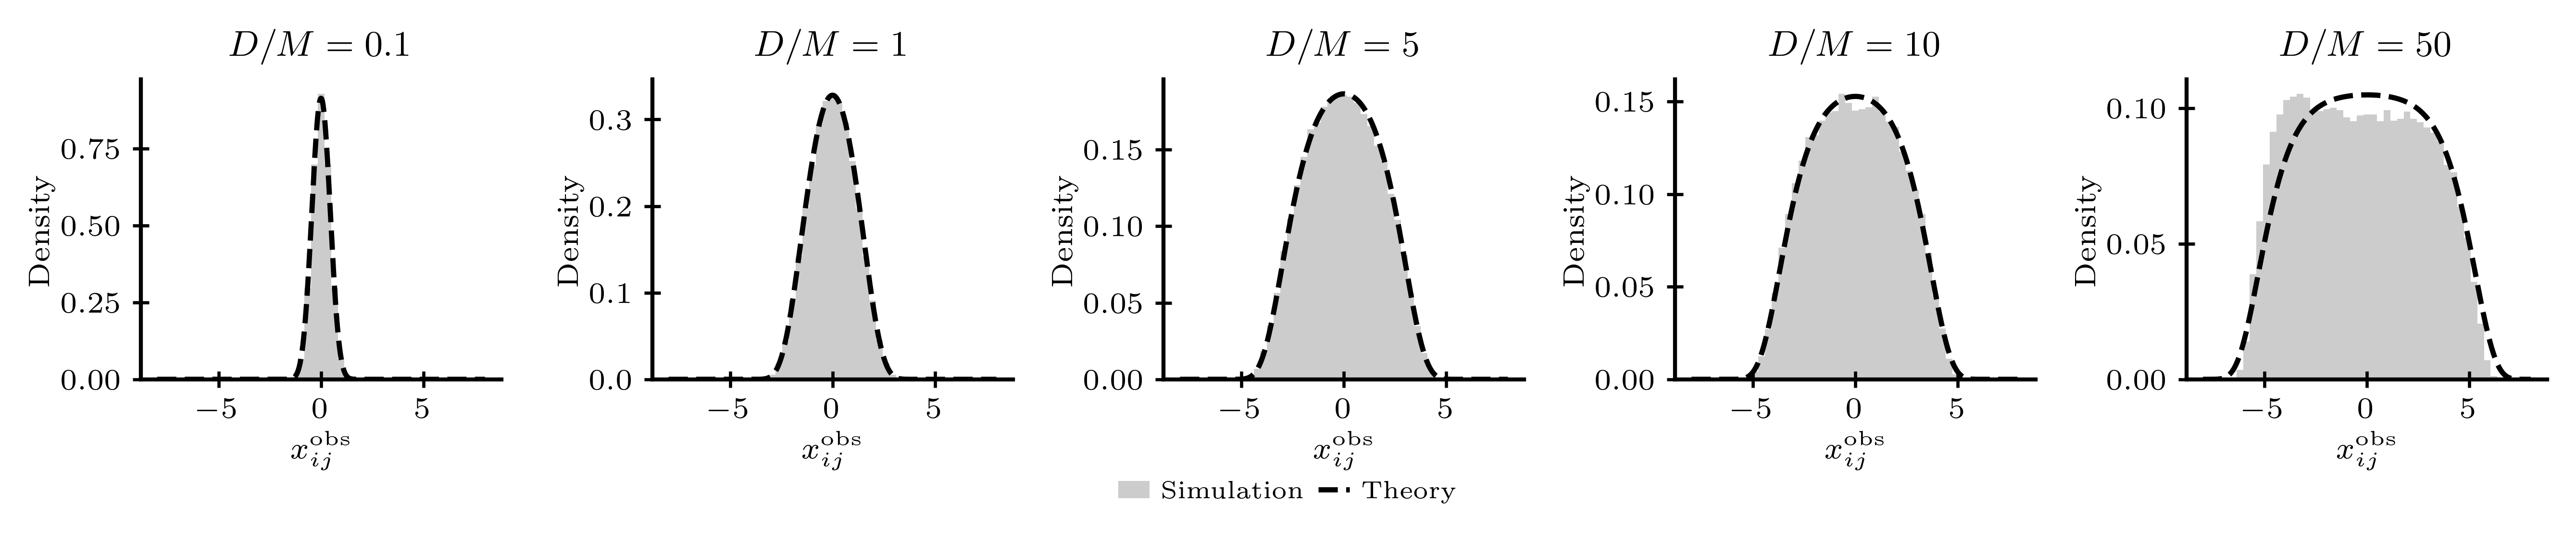

In [ ]:
fig, ax = plt.subplots(1, 5, figsize=(9, 1.8), layout='tight')
x_bound = 8
xs = np.linspace(-x_bound, x_bound, 1000)
D = 1

bins = np.linspace(-x_bound, x_bound, 50)

ax[0].hist(lib.get_empirical_log_ratios(c_vweak[:, 0], c_vweak[:, 1], threshold=0, base=np.exp(1)), density=True, bins=bins, alpha=0.2, color='black')

ax[1].hist(lib.get_empirical_log_ratios(c_weak[:, 0], c_weak[:, 1], threshold=0, base=np.exp(1)), density=True, bins=bins, alpha=0.2, color='black', label='Simulation')

ax[2].hist(lib.get_empirical_log_ratios(c_medium[:, 0], c_medium[:, 1], threshold=0, base=np.exp(1)), density=True, bins=bins, alpha=0.2, color='black')

ax[3].hist(lib.get_empirical_log_ratios(c_strong[:, 0], c_strong[:, 1], threshold=0, base=np.exp(1)), density=True, bins=bins, alpha=0.2, color='black')

ax[4].hist(lib.get_empirical_log_ratios(c_vstrong[:, 0], c_vstrong[:, 1], threshold=0, base=np.exp(1)), density=True, bins=bins, alpha=0.2, color='black')

ax[0].plot(xs, density_x_white_noise(xs, M=1, D=0.1), linestyle='--', c='black')
ax[1].plot(xs, density_x_white_noise(xs, M=1, D=1), label='Theory', linestyle='--', c='black')
ax[2].plot(xs, density_x_white_noise(xs, M=1, D=5), linestyle='--', c='black')
ax[3].plot(xs, density_x_white_noise(xs, M=1, D=10), linestyle='--', c='black')
ax[4].plot(xs, density_x_white_noise(xs, M=1, D=50), linestyle='--', c='black')

for axes in ax:
    axes.set_xlabel(r'$x^{\mathrm{obs}}_{ij}$')
    axes.set_ylabel('Density')
    
ax[0].set_title(r"$D/M = 0.1$")
ax[1].set_title(r"$D/M = 1$")
ax[2].set_title(r"$D/M = 5$")
ax[3].set_title(r"$D/M = 10$")
ax[4].set_title(r"$D/M = 50$")

handles, labels = ax[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center",
           bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False)
plt.savefig('../../figures/spatial_variability/white_noise.svg', bbox_inches='tight', dpi=200, transparent=True);

In [7]:
print(f"D/M = 0.1, Seff end = {lib.get_average_simpsons_diversity(c_vweak)}")
print(f"D/M = 1, Seff end = {lib.get_average_simpsons_diversity(c_weak)}")
print(f"D/M = 5, Seff end = {lib.get_average_simpsons_diversity(c_medium)}")
print(f"D/M = 10, Seff end = {lib.get_average_simpsons_diversity(c_strong)}")
print(f"D/M = 50, Seff end = {lib.get_average_simpsons_diversity(c_vstrong)}")

D/M = 0.1, Seff end = 85389.49705804331
D/M = 1, Seff end = 16380.744087394041
D/M = 5, Seff end = 300.45378545544213
D/M = 10, Seff end = 13.370063568874613
D/M = 50, Seff end = 1.980185621117307


## pAFD - coloured noise

In [8]:
c_weak_coloured = np.load(DATA_PATH + "sim_results/two_patches_weak_coloured_noise.npz",  allow_pickle=True)["c"][-1]
c_coloured = np.load(DATA_PATH + "sim_results/two_patches_coloured_noise.npz",  allow_pickle=True)["c"][-1]
c_strong_coloured = np.load(DATA_PATH + "sim_results/two_patches_strong_coloured_noise.npz",  allow_pickle=True)["c"][-1]
c_vstrong_coloured = np.load(DATA_PATH + "sim_results/two_patches_vstrong_coloured_noise.npz",  allow_pickle=True)["c"][-1]

In [9]:
def unnormalized_density_x_coloured_noise(x, M, D, lamb):
    
    return (1 + M/lamb * np.cosh(x)) * np.exp(- M /(2 * D) * (1 + M / (2 * lamb) * np.cosh(x)) * np.cosh(x))

def partition_function_x_coloured_noise(M, D, lamb, x_range=100):
    
    Z = integrate.quad(unnormalized_density_x_coloured_noise, -x_range, x_range, args=(M, D, lamb))[0]
    
    return Z

def density_x_coloured_noise(x, M, D, lamb):
    
    Z = partition_function_x_coloured_noise(M, D, lamb)
    
    return 1 /Z * unnormalized_density_x_coloured_noise(x, M, D, lamb) 

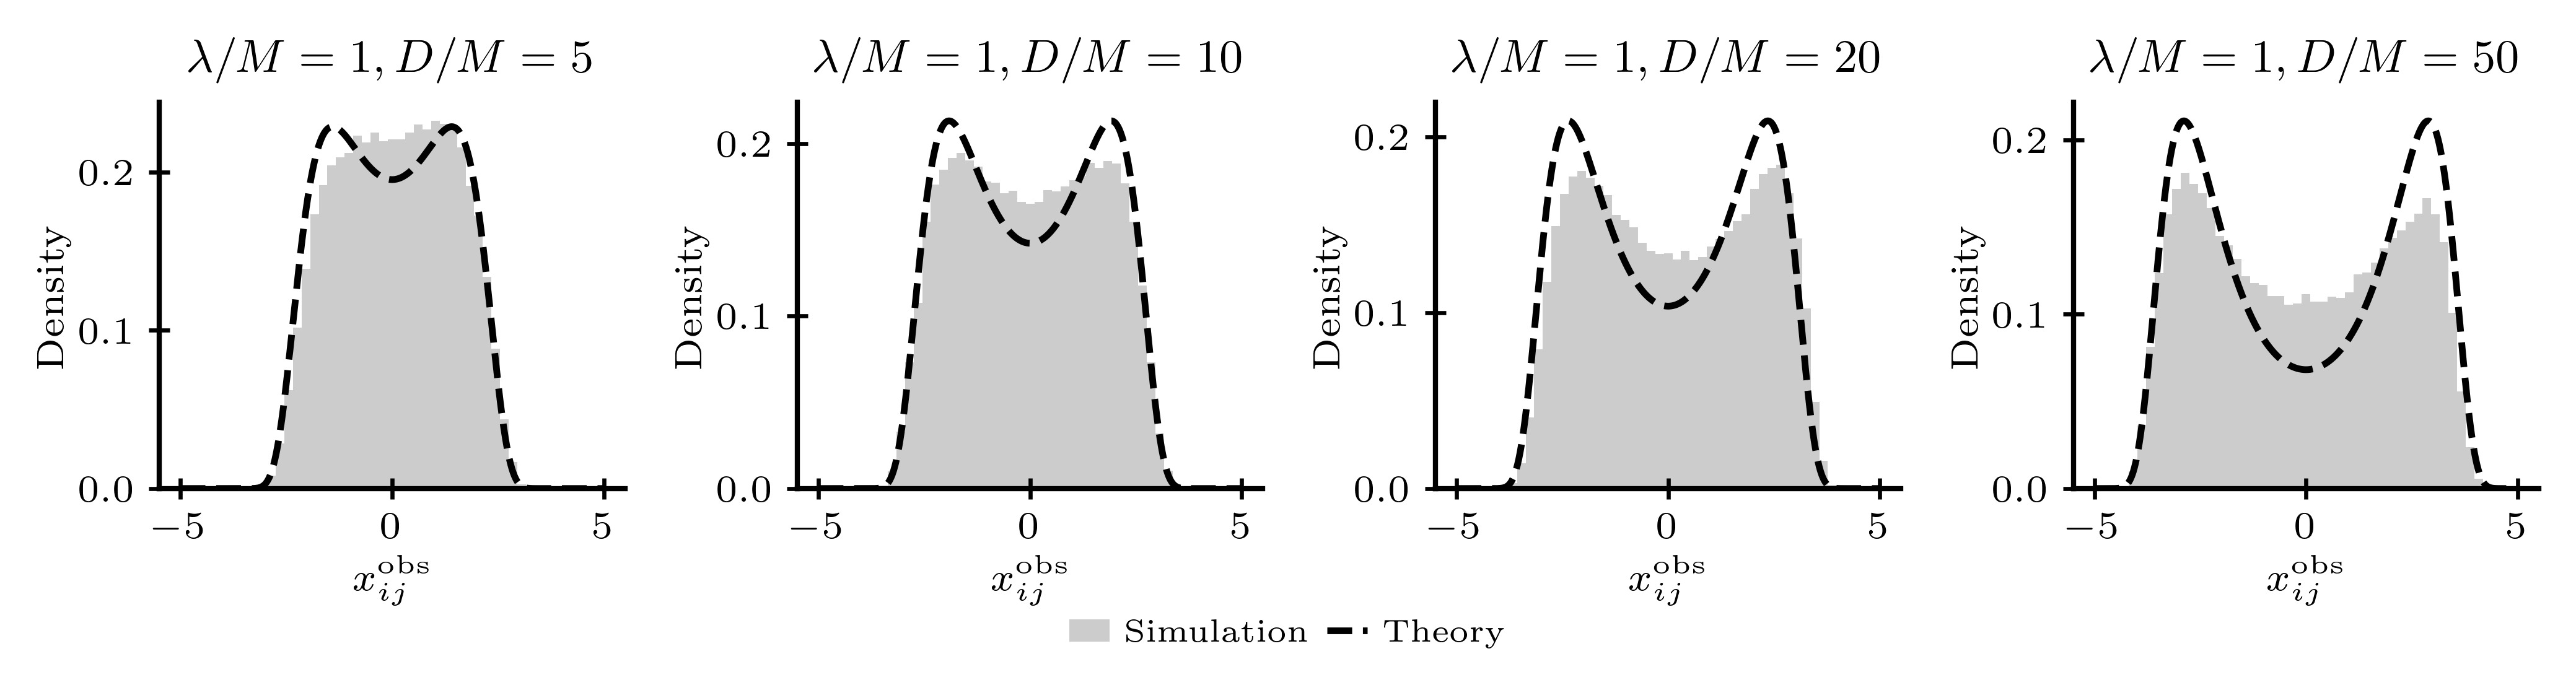

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(7, 1.8), layout='tight')
x_bound = 5
xs = np.linspace(-x_bound, x_bound, 1000)

bins = np.linspace(-x_bound, x_bound, 50)

ax[0].hist(lib.get_empirical_log_ratios(c_weak_coloured[:, 0], c_weak_coloured[:, 1], threshold=0, base=np.exp(1)), density=True, bins=bins, alpha=0.2, color='black')

ax[1].hist(lib.get_empirical_log_ratios(c_coloured[:, 0], c_coloured[:, 1], threshold=0, base=np.exp(1)), density=True, bins=bins, alpha=0.2, color='black', label='Simulation')

ax[2].hist(lib.get_empirical_log_ratios(c_strong_coloured[:, 0], c_strong_coloured[:, 1], threshold=0, base=np.exp(1)), density=True, bins=bins, alpha=0.2, color='black')

ax[3].hist(lib.get_empirical_log_ratios(c_vstrong_coloured[:, 0], c_vstrong_coloured[:, 1], threshold=0, base=np.exp(1)), density=True, bins=bins, alpha=0.2, color='black')

ax[0].plot(xs, density_x_coloured_noise(xs, M=1, D=5, lamb=1), linestyle='--', c='black')
ax[1].plot(xs, density_x_coloured_noise(xs, M=1, D=10, lamb=1), linestyle='--', c='black', label='Theory')
ax[2].plot(xs, density_x_coloured_noise(xs, M=1, D=20, lamb=1), linestyle='--', c='black')
ax[3].plot(xs, density_x_coloured_noise(xs, M=1, D=50, lamb=1), linestyle='--', c='black')

for axes in ax:
    axes.set_xlabel(r'$x^{\mathrm{obs}}_{ij}$')
    axes.set_ylabel('Density')
    
ax[0].set_title(r"$\lambda/M = 1, D/M = 5$")
ax[1].set_title(r"$\lambda/M = 1, D/M = 10$")
ax[2].set_title(r"$\lambda/M = 1, D/M = 20$")
ax[3].set_title(r"$\lambda/M = 1, D/M = 50$")

handles, labels = ax[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center",
           bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False)

plt.savefig('../../figures/spatial_variability/coloured_noise.svg', bbox_inches='tight', dpi=200, transparent=True);

In [11]:
print(f"D/M = 5, Seff end = {lib.get_average_simpsons_diversity(c_weak_coloured)}")
print(f"D/M = 10, Seff end = {lib.get_average_simpsons_diversity(c_coloured)}")
print(f"D/M = 20, Seff end = {lib.get_average_simpsons_diversity(c_strong_coloured)}")
print(f"D/M = 50, Seff end = {lib.get_average_simpsons_diversity(c_vstrong_coloured)}")

D/M = 5, Seff end = 170.87392137383426
D/M = 10, Seff end = 28.030191105913982
D/M = 20, Seff end = 5.9983208363987925
D/M = 50, Seff end = 6.211914059735028
